<a href="https://colab.research.google.com/github/kevinpark138/inventory-policy-sim/blob/main/notebooks/inventory_policy_sim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Inventory policy and safety stock simulator

**Question:** For a set of Walmart products, which reorder policy gives the best tradeoff between running out of stock and holding too much inventory? And does the textbook safety stock formula hold up for slow, irregular sellers?

**Data:** Walmart M5 Forecasting dataset (Kaggle), one store (CA_1), last 2 years of daily unit sales.

**What this notebook does:**
1. Picks 40 products: 10 steady sellers and 30 intermittent sellers
2. Compares 4 simple forecasting methods
3. Sets (s, Q) reorder policies at 90%, 95%, and 99% service targets using two methods: the normal-distribution formula and an empirical (data-based) method
4. Simulates one year of daily inventory using actual demand, and measures stockouts, fill rate, inventory dollars, and cost

Year 1 is used to set parameters. Year 2 is used only for testing, so the policies never "see" the demand they are tested on.

## 1. Setup

In [13]:
# If you're in Google Colab, this connects your Google Drive so the notebook can read the data files.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # not in Colab, running locally

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statistics import NormalDist

# ---- Settings (change these if needed) ----
DATA_DIR = os.environ.get("M5_DATA_DIR", "/content/drive/MyDrive/M5")  # folder with the 3 CSV files
STORE = "CA_1"
N_DAYS = 730           # last 2 years of data
TRAIN_DAYS = 365       # year 1 = set parameters, year 2 = test

# ---- Inventory assumptions (stated, not from the data) ----
LEAD_TIME = 7          # days from placing an order to receiving it
ORDER_COST = 25.0      # $ per order (admin, transport, receiving)
HOLDING_RATE = 0.25    # yearly holding cost as a share of the item's price
SERVICE_LEVELS = [0.90, 0.95, 0.99]

os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("Data folder:", DATA_DIR)

Data folder: /content/drive/MyDrive/M5


## 2. Load the data

The sales file has one row per product per store and one column per day (`d_1` to `d_1941`). It's large, so only the last 730 day columns are loaded.

In [15]:
sales_path = f"{DATA_DIR}/sales_train_evaluation.csv"
header = pd.read_csv(sales_path, nrows=0).columns
all_day_cols = [c for c in header if c.startswith("d_")]
day_cols = all_day_cols[-N_DAYS:]
train_cols = day_cols[:TRAIN_DAYS]
test_cols = day_cols[TRAIN_DAYS:]

id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id"]
sales = pd.read_csv(sales_path, usecols=id_cols + day_cols,
                    dtype={c: "int32" for c in day_cols})
store = sales[sales["store_id"] == STORE].reset_index(drop=True)

cal = pd.read_csv(f"{DATA_DIR}/calendar.csv", usecols=["d", "date", "wm_yr_wk"])
cal["date"] = pd.to_datetime(cal["date"])
prices = pd.read_csv(f"{DATA_DIR}/sell_prices.csv")
prices = prices[prices["store_id"] == STORE]

d2date = cal.set_index("d")["date"]
print(f"{len(store):,} products in {STORE}")
print("Train:", d2date[train_cols[0]].date(), "to", d2date[train_cols[-1]].date())
print("Test: ", d2date[test_cols[0]].date(), "to", d2date[test_cols[-1]].date())

3,049 products in CA_1
Train: 2014-05-24 to 2015-05-23
Test:  2015-05-24 to 2016-05-22


## 3. Pick the products

Stats are calculated on **year 1 only**, so the choice of products doesn't use test data.

- **Group A (steady):** the 10 highest-volume products that sold on at least 90% of days
- **Group B (intermittent):** 30 random products with zero sales on 40% to 60% of days, averaging at least 0.5 units/day

Why two groups: the standard safety stock formula assumes demand follows a normal (bell curve) distribution. That's roughly true for steady sellers and usually false for items that often sell zero. Testing both shows where the textbook method breaks.

In [16]:
train = store[train_cols]
stats = pd.DataFrame({
    "total_units": train.sum(axis=1),
    "pct_zero_days": (train == 0).mean(axis=1),
    "avg_daily": train.mean(axis=1),
    "std_daily": train.std(axis=1),
})
stats["cv"] = stats["std_daily"] / stats["avg_daily"]   # coefficient of variation = how "noisy" demand is
store = pd.concat([store, stats], axis=1)

group_a = (store[store["pct_zero_days"] < 0.10]
           .sort_values("total_units", ascending=False).head(10).copy())
group_a["group"] = "A_steady"

pool_b = store[(store["pct_zero_days"].between(0.40, 0.60)) & (store["avg_daily"] >= 0.5)]
group_b = pool_b.sample(min(30, len(pool_b)), random_state=42).copy()
group_b["group"] = "B_intermittent"

skus = pd.concat([group_a, group_b]).reset_index(drop=True)

# Unit price: median shelf price during year 1
train_weeks = cal[cal["d"].isin(train_cols)]["wm_yr_wk"].unique()
p = prices[prices["wm_yr_wk"].isin(train_weeks)].groupby("item_id")["sell_price"].median()
p_all = prices.groupby("item_id")["sell_price"].median()   # backup if no year-1 price
skus["price"] = skus["item_id"].map(p).fillna(skus["item_id"].map(p_all))

skus[["item_id", "group", "avg_daily", "std_daily", "cv", "pct_zero_days", "price"]]

,item_id,group,avg_daily,std_daily,cv,pct_zero_days,price
0,FOODS_3_586,A_steady,46.852,15.966,0.341,0.003,1.680
1,FOODS_3_252,A_steady,44.751,18.711,0.418,0.003,1.580
2,FOODS_3_282,A_steady,31.353,18.150,0.579,0.047,2.500
3,FOODS_3_714,A_steady,27.732,13.372,0.482,0.003,1.580
4,FOODS_3_064,A_steady,22.304,9.128,0.409,0.016,1.080
5,FOODS_3_739,A_steady,20.559,12.980,0.631,0.066,1.500
6,FOODS_3_555,A_steady,20.523,7.891,0.384,0.003,1.680
7,FOODS_2_197,A_steady,19.868,10.170,0.512,0.033,3.280
8,FOODS_3_607,A_steady,19.767,11.514,0.582,0.027,1.980
9,FOODS_3_741,A_steady,18.921,12.869,0.680,0.027,1.250


## 4. Explore the demand

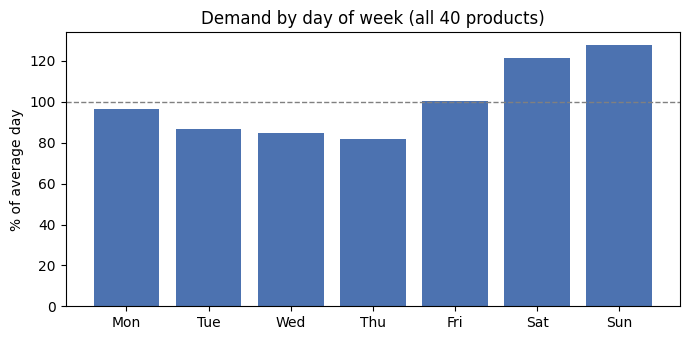

In [17]:
long = skus.melt(id_vars=["item_id", "group"], value_vars=day_cols,
                 var_name="d", value_name="units")
long = long.merge(cal[["d", "date"]], on="d")
long["period"] = np.where(long["d"].isin(train_cols), "train", "test")

# Weekly pattern: average units by day of week, as % of each product's own average
long["weekday"] = long["date"].dt.day_name().str[:3]
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
idx = long.groupby(["item_id", "weekday"])["units"].mean() / long.groupby("item_id")["units"].mean()
weekday_index = idx.groupby("weekday").mean().reindex(order) * 100

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(weekday_index.index, weekday_index.values, color="#4C72B0")
ax.axhline(100, color="gray", lw=1, ls="--")
ax.set_ylabel("% of average day")
ax.set_title("Demand by day of week (all 40 products)")
plt.tight_layout(); plt.savefig("figures/weekday_pattern.png", dpi=150); plt.show()

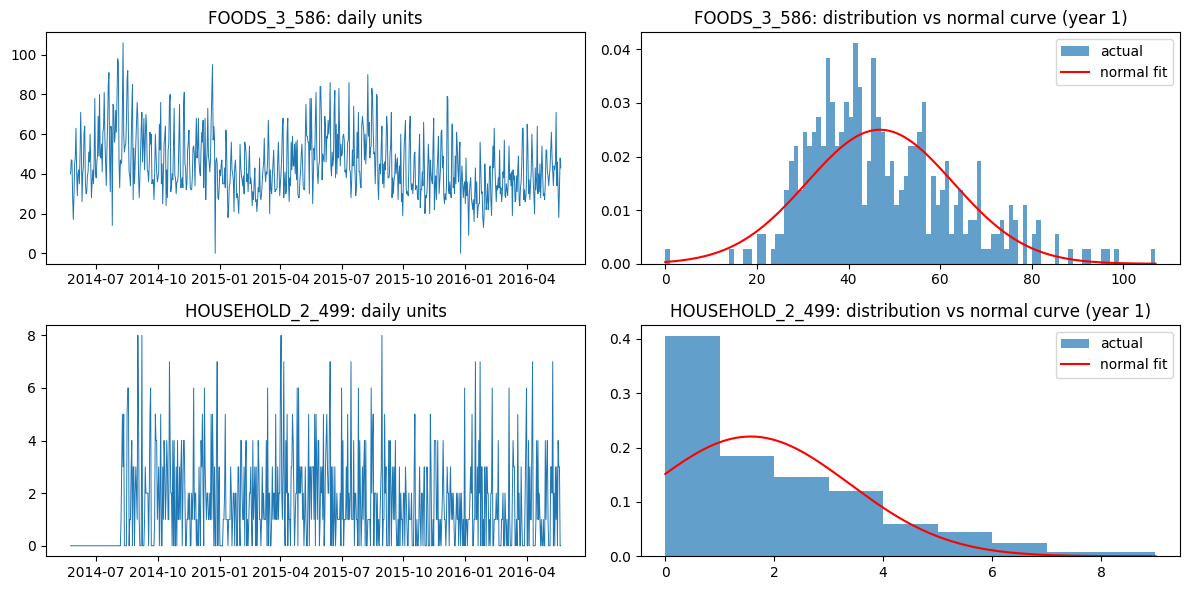

In [18]:
ex_a = skus[skus["group"] == "A_steady"]["item_id"].iloc[0]
ex_b = skus[skus["group"] == "B_intermittent"]["item_id"].iloc[0]

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for row, item in enumerate([ex_a, ex_b]):
    s = long[long["item_id"] == item]
    axes[row, 0].plot(s["date"], s["units"], lw=0.7)
    axes[row, 0].set_title(f"{item}: daily units")
    tr = s[s["period"] == "train"]["units"]
    axes[row, 1].hist(tr, bins=range(0, int(tr.max()) + 2), density=True, alpha=0.7, label="actual")
    x = np.linspace(0, tr.max() + 1, 200)
    nd = NormalDist(tr.mean(), max(tr.std(), 1e-6))
    axes[row, 1].plot(x, [nd.pdf(v) for v in x], "r-", label="normal fit")
    axes[row, 1].set_title(f"{item}: distribution vs normal curve (year 1)")
    axes[row, 1].legend()
plt.tight_layout(); plt.savefig("figures/demand_examples.png", dpi=150); plt.show()

Look at the bottom-right chart. If the bars pile up at zero and the red curve doesn't match, the normal assumption is a poor fit for that product.

## 5. Forecasting comparison

Each method predicts tomorrow's demand using only data up to today (one-step-ahead), scored on year 2.

- **Naive:** tomorrow = today
- **Seasonal naive:** tomorrow = same weekday last week
- **28-day moving average**
- **Simple exponential smoothing (SES):** a weighted average that gives more weight to recent days. The weight `alpha` is tuned on year 1.

**Error metric: WAPE** = total absolute error ÷ total actual units. MAPE (the usual % error) breaks when actual demand is 0, which happens a lot here.

In [19]:
def ses_forecast(y, alpha):
    # f[t] = forecast for day t made at end of day t-1
    f = np.empty(len(y)); f[0] = y[0]
    for t in range(1, len(y)):
        f[t] = alpha * y[t - 1] + (1 - alpha) * f[t - 1]
    return f

def wape(actual, fcst):
    return np.abs(actual - fcst).sum() / max(actual.sum(), 1e-9)

fc_rows = []
for _, r in skus.iterrows():
    y = r[day_cols].to_numpy(dtype=float)
    n_tr = TRAIN_DAYS
    test_y = y[n_tr:]

    # tune alpha on year 1 (skip the first 28 days as warm-up)
    alphas = np.round(np.arange(0.02, 0.52, 0.02), 2)
    best_alpha = min(alphas, key=lambda a: wape(y[28:n_tr], ses_forecast(y[:n_tr], a)[28:]))

    fc = {
        "Naive": y[n_tr - 1:-1],
        "Seasonal naive": y[n_tr - 7:-7],
        "28-day MA": np.array([y[t - 28:t].mean() for t in range(n_tr, len(y))]),
        "SES": ses_forecast(y, best_alpha)[n_tr:],
    }
    for m, f in fc.items():
        fc_rows.append({"item_id": r["item_id"], "group": r["group"], "method": m,
                        "WAPE": wape(test_y, f),
                        "bias": (f.sum() - test_y.sum()) / max(test_y.sum(), 1e-9),
                        "alpha": best_alpha if m == "SES" else np.nan})
fc_df = pd.DataFrame(fc_rows)

fc_summary = fc_df.pivot_table(index="method", columns="group", values="WAPE", aggfunc="mean")
fc_summary["All"] = fc_df.groupby("method")["WAPE"].mean()
fc_summary = fc_summary.sort_values("All")
best_counts = fc_df.loc[fc_df.groupby("item_id")["WAPE"].idxmin(), "method"].value_counts()
print("Average WAPE by method (lower is better):")
display(fc_summary)
print("\nNumber of products where each method was most accurate:")
print(best_counts.to_string())
fc_df.to_csv("outputs/forecast_results.csv", index=False)

Average WAPE by method (lower is better):


group,A_steady,B_intermittent,All
method,,,
28-day MA,0.357,0.962,0.811
SES,0.350,0.968,0.813
Seasonal naive,0.380,1.154,0.960
Naive,0.398,1.152,0.964



Number of products where each method was most accurate:
method
SES               20
28-day MA         15
Seasonal naive     5


## 6. Inventory policies

Every product uses an **(s, Q) policy**: check stock daily, and when inventory position (on hand + already on order) drops to the reorder point **s** or below, order **Q** units. The order arrives after the 7-day lead time.

**Order quantity Q (same for both methods): Economic Order Quantity**

$$Q = \sqrt{\frac{2DS}{H}}$$

D = yearly demand, S = cost per order, H = yearly holding cost per unit (price × 25%).

**Reorder point s, two ways:**

- **Normal method (textbook):** $s = \mu L + z\,\sigma\sqrt{L}$, where μ and σ are daily mean and standard deviation from year 1, L = lead time, and z comes from the service target (90% → 1.28, 95% → 1.64, 99% → 2.33).
- **Empirical method:** take every 7-day stretch in year 1, add up demand, and set s at the 90th/95th/99th percentile of those totals. No bell-curve assumption.

**Service target here = cycle service level:** the chance of *not* running out while waiting for an order to arrive.

In [20]:
def policy_params(train_y, price, sl, method):
    mu, sigma = train_y.mean(), train_y.std(ddof=1)
    D = mu * 365
    H = price * HOLDING_RATE
    Q = max(1, round(math.sqrt(2 * D * ORDER_COST / H))) if D > 0 else 1
    if method == "Normal":
        z = NormalDist().inv_cdf(sl)
        s = mu * LEAD_TIME + z * sigma * math.sqrt(LEAD_TIME)
    else:  # Empirical
        lt_demand = pd.Series(train_y).rolling(LEAD_TIME).sum().dropna()
        s = np.quantile(lt_demand, sl)
    return math.ceil(s), Q

def simulate(demand, s, Q, price):
    # Daily (s, Q) simulation with lost sales: if a customer finds the shelf empty, the sale is lost.
    n = len(demand)
    on_hand = s + Q                  # start the year with a full cycle of stock
    arrivals = np.zeros(n + LEAD_TIME + 1)
    sold = np.zeros(n); lost = np.zeros(n); end_inv = np.zeros(n)
    orders = []                      # day each order was placed
    on_order = 0
    for t in range(n):
        on_hand += arrivals[t]; on_order -= arrivals[t]      # receive orders due today
        sold[t] = min(on_hand, demand[t]); lost[t] = demand[t] - sold[t]
        on_hand -= sold[t]
        while on_hand + on_order <= s:                       # inventory position at or below s
            arrivals[t + LEAD_TIME] += Q; on_order += Q
            orders.append(t)
        end_inv[t] = on_hand
    # cycle service: for each order, did we run out before it arrived?
    cycles = [lost[t + 1:t + LEAD_TIME + 1].sum() > 0 for t in orders if t + LEAD_TIME < n]
    return {
        "fill_rate": sold.sum() / max(demand.sum(), 1e-9),
        "cycles": len(cycles),
        "stockout_cycles": int(sum(cycles)),
        "stockout_days": int((lost > 0).sum()),
        "orders": len(orders),
        "avg_inv_units": end_inv.mean(),
        "avg_inv_$": end_inv.mean() * price,
        "holding_cost": end_inv.mean() * price * HOLDING_RATE * n / 365,
        "ordering_cost": len(orders) * ORDER_COST,
        "lost_units": lost.sum(),
        "lost_revenue": lost.sum() * price,
    }

sim_rows = []
for _, r in skus.iterrows():
    y = r[day_cols].to_numpy(dtype=float)
    tr_y, te_y = y[:TRAIN_DAYS], y[TRAIN_DAYS:]
    for method in ["Normal", "Empirical"]:
        for sl in SERVICE_LEVELS:
            s, Q = policy_params(tr_y, r["price"], sl, method)
            res = simulate(te_y, s, Q, r["price"])
            sim_rows.append({"item_id": r["item_id"], "group": r["group"], "method": method,
                             "target": sl, "s": s, "Q": Q, **res})
sim = pd.DataFrame(sim_rows)
sim["total_cost"] = sim["holding_cost"] + sim["ordering_cost"]
sim["cycle_service"] = 1 - sim["stockout_cycles"] / sim["cycles"].clip(lower=1)
sim.to_csv("outputs/simulation_by_sku.csv", index=False)
sim.head(6)

,item_id,group,method,target,s,Q,fill_rate,cycles,stockout_cycles,stockout_days,orders,avg_inv_units,avg_inv_$,holding_cost,ordering_cost,lost_units,lost_revenue,total_cost,cycle_service
0,FOODS_3_586,A_steady,Normal,0.900,383,1427,0.996,10,2,2,10,828.422,"1,391.749",347.937,250.000,62.000,104.160,597.937,0.800
1,FOODS_3_586,A_steady,Normal,0.950,398,1427,1.000,10,0,0,10,837.978,"1,407.803",351.951,250.000,0.000,0.000,601.951,1.000
2,FOODS_3_586,A_steady,Normal,0.990,427,1427,1.000,10,0,0,10,866.978,"1,456.523",364.131,250.000,0.000,0.000,614.131,1.000
3,FOODS_3_586,A_steady,Empirical,0.900,407,1427,1.000,10,0,0,10,846.978,"1,422.923",355.731,250.000,0.000,0.000,605.731,1.000
4,FOODS_3_586,A_steady,Empirical,0.950,436,1427,1.000,10,0,0,10,875.978,"1,471.643",367.911,250.000,0.000,0.000,617.911,1.000
5,FOODS_3_586,A_steady,Empirical,0.990,482,1427,1.000,10,0,0,10,921.978,"1,548.923",387.231,250.000,0.000,0.000,637.231,1.000


## 7. Results

In [21]:
# One row per group / method / target. Inventory and cost are totals across the group's products;
# fill rate is the average per product.
summary = (sim.groupby(["group", "method", "target"])
           .agg(**{"cycles": ("cycles", "sum"),
                   "stockout_cycles": ("stockout_cycles", "sum"),
                   "fill_rate": ("fill_rate", "mean"),
                   "stockout_days_per_sku": ("stockout_days", "mean"),
                   "avg_inventory_$": ("avg_inv_$", "sum"),
                   "total_cost_$": ("total_cost", "sum"),
                   "lost_revenue_$": ("lost_revenue", "sum")})
           .reset_index())
# Pooled across products: share of all replenishment cycles with no stockout
summary.insert(3, "achieved_cycle_service", 1 - summary["stockout_cycles"] / summary["cycles"])
summary.to_csv("outputs/summary.csv", index=False)
summary

,group,method,target,achieved_cycle_service,cycles,stockout_cycles,fill_rate,stockout_days_per_sku,avg_inventory_$,total_cost_$,lost_revenue_$
0,A_steady,Empirical,0.900,0.959,73,3,0.999,0.400,"11,512.533","4,728.133",104.760
1,A_steady,Empirical,0.950,0.986,73,1,0.999,0.200,"11,922.142","4,830.535",56.160
2,A_steady,Empirical,0.990,0.986,73,1,1.000,0.100,"12,433.569","4,958.392",32.400
3,A_steady,Normal,0.900,0.918,73,6,0.998,0.700,"10,991.887","4,597.972",230.560
4,A_steady,Normal,0.950,0.959,73,3,0.999,0.400,"11,209.174","4,652.294",108.000
5,A_steady,Normal,0.990,0.986,73,1,0.999,0.200,"11,646.632","4,761.658",56.160
6,B_intermittent,Empirical,0.900,0.893,56,6,0.997,0.433,"9,473.860","3,818.465",92.180
7,B_intermittent,Empirical,0.950,0.911,56,5,0.998,0.300,"9,678.093","3,869.523",61.510
8,B_intermittent,Empirical,0.990,0.964,56,2,0.999,0.133,"10,003.574","3,950.894",31.940
9,B_intermittent,Normal,0.900,0.875,56,7,0.997,0.433,"9,472.790","3,818.197",100.440


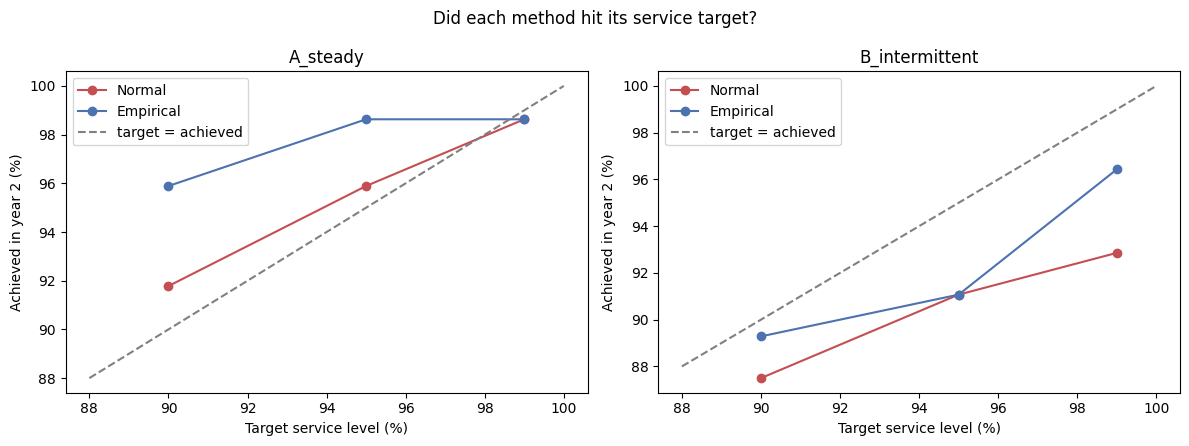

In [22]:
colors = {"Normal": "#C44E52", "Empirical": "#4C72B0"}
groups = list(summary["group"].unique())

fig, axes = plt.subplots(1, len(groups), figsize=(6 * len(groups), 4.5), squeeze=False)
for ax, g in zip(axes[0], groups):
    for m in ["Normal", "Empirical"]:
        d = summary[(summary["group"] == g) & (summary["method"] == m)]
        ax.plot(d["target"] * 100, d["achieved_cycle_service"] * 100, "o-", color=colors[m], label=m)
    ax.plot([88, 100], [88, 100], "--", color="gray", label="target = achieved")
    ax.set_xlabel("Target service level (%)"); ax.set_ylabel("Achieved in year 2 (%)")
    ax.set_title(g); ax.legend()
fig.suptitle("Did each method hit its service target?")
plt.tight_layout(); plt.savefig("figures/target_vs_achieved.png", dpi=150); plt.show()

Points on the dashed line hit their target exactly. Points below it ran out of stock more often than promised.

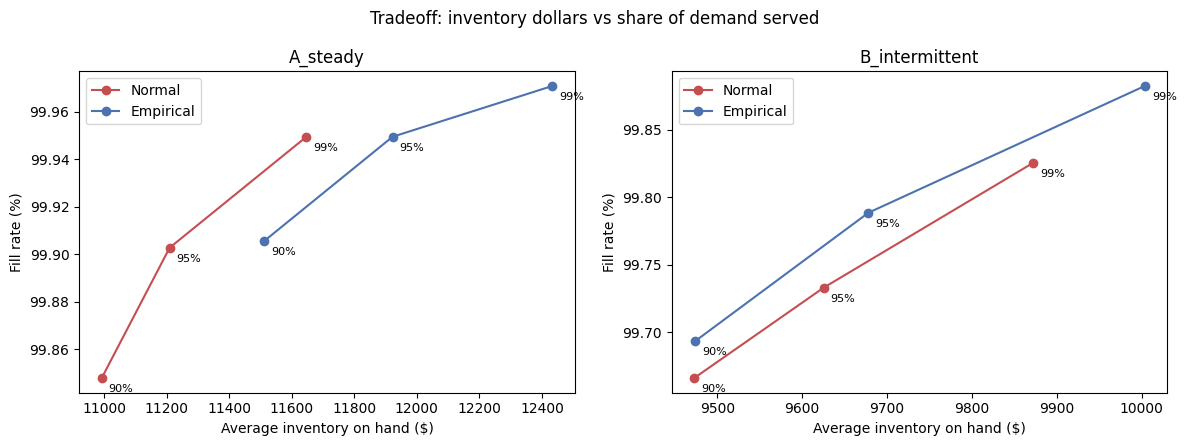

In [23]:
fig, axes = plt.subplots(1, len(groups), figsize=(6 * len(groups), 4.5), squeeze=False)
for ax, g in zip(axes[0], groups):
    for m in ["Normal", "Empirical"]:
        d = summary[(summary["group"] == g) & (summary["method"] == m)]
        ax.plot(d["avg_inventory_$"], d["fill_rate"] * 100, "o-", color=colors[m], label=m)
        for _, row in d.iterrows():
            ax.annotate(f"{row['target']:.0%}", (row["avg_inventory_$"], row["fill_rate"] * 100),
                        textcoords="offset points", xytext=(5, -10), fontsize=8)
    ax.set_xlabel("Average inventory on hand ($)"); ax.set_ylabel("Fill rate (%)")
    ax.set_title(g); ax.legend()
fig.suptitle("Tradeoff: inventory dollars vs share of demand served")
plt.tight_layout(); plt.savefig("figures/cost_vs_service.png", dpi=150); plt.show()

## 8. Key numbers for the write-up

This cell turns the results into plain sentences. Use these exact numbers in your README and resume, since they come from your run.

In [24]:
def row(g, m, t):
    return summary[(summary["group"] == g) & (summary["method"] == m) & (summary["target"] == t)].iloc[0]

lines = []
lines.append(f"Products analyzed: {len(skus)} ({(skus['group']=='A_steady').sum()} steady, "
             f"{(skus['group']=='B_intermittent').sum()} intermittent), store {STORE}, "
             f"{TRAIN_DAYS} days to set parameters and {N_DAYS-TRAIN_DAYS} days to test.")
best = fc_summary.index[0]
lines.append(f"Most accurate forecast on average: {best} "
             f"(WAPE {fc_summary.loc[best,'All']:.1%}); naive WAPE was {fc_summary.loc['Naive','All']:.1%}.")
for g in groups:
    n95, e95 = row(g, "Normal", 0.95), row(g, "Empirical", 0.95)
    lines.append(f"[{g}] 95% target -> Normal achieved {n95['achieved_cycle_service']:.1%} cycle service "
                 f"(fill rate {n95['fill_rate']:.1%}, ${n95['avg_inventory_$']:,.0f} avg inventory); "
                 f"Empirical achieved {e95['achieved_cycle_service']:.1%} "
                 f"(fill rate {e95['fill_rate']:.1%}, ${e95['avg_inventory_$']:,.0f}).")
    for m in ["Normal", "Empirical"]:
        lo, hi = row(g, m, 0.95), row(g, m, 0.99)
        inv_up = hi["avg_inventory_$"] / lo["avg_inventory_$"] - 1 if lo["avg_inventory_$"] else float("nan")
        lines.append(f"[{g}] {m}: moving 95% -> 99% changed inventory $ by {inv_up:+.0%} "
                     f"and fill rate by {(hi['fill_rate']-lo['fill_rate'])*100:.1f} points.")
text = "\n".join(lines)
print(text)
with open("outputs/key_numbers.txt", "w") as f:
    f.write(text)

Products analyzed: 40 (10 steady, 30 intermittent), store CA_1, 365 days to set parameters and 365 days to test.
Most accurate forecast on average: 28-day MA (WAPE 81.1%); naive WAPE was 96.4%.
[A_steady] 95% target -> Normal achieved 95.9% cycle service (fill rate 99.9%, $11,209 avg inventory); Empirical achieved 98.6% (fill rate 99.9%, $11,922).
[A_steady] Normal: moving 95% -> 99% changed inventory $ by +4% and fill rate by 0.0 points.
[A_steady] Empirical: moving 95% -> 99% changed inventory $ by +4% and fill rate by 0.0 points.
[B_intermittent] 95% target -> Normal achieved 91.1% cycle service (fill rate 99.7%, $9,625 avg inventory); Empirical achieved 91.1% (fill rate 99.8%, $9,678).
[B_intermittent] Normal: moving 95% -> 99% changed inventory $ by +3% and fill rate by 0.1 points.
[B_intermittent] Empirical: moving 95% -> 99% changed inventory $ by +3% and fill rate by 0.1 points.


## 9. Limitations and next steps

**Assumptions to be upfront about:**
- Lead time is a fixed 7 days. Real lead times vary, which would require more safety stock.
- Order cost ($25) and holding rate (25%/year) are assumptions, not Walmart's numbers.
- Unmet demand is treated as a lost sale. In reality some customers come back later, and the dataset only shows sales, not true demand when the shelf was empty.
- Parameters are set once from year 1 and never updated.

**Next steps:**
- Update s and Q monthly using the best forecast instead of a fixed year-1 average
- Add variable lead times
- Try a periodic review policy (order every R days), which is closer to how many stores reorder
- Expand from 15 products to a full department

In [25]:
# Bundle charts and result tables into one zip and download it
!zip -qr results.zip figures outputs
from google.colab import files
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>